# Marketing Mix Modeling for GLUCOREN
## From spend to a defensible reallocation memo
Applied Data Science and AI in Pharma Commercial · Columbia University · Fall 2026 | @author: Michael Chen, 10/12/2026
- Deliverable: one zip with (a) a Jupyter notebook and (b) a two-page memo as PDF
- Data: glucoren_weekly_mmm.csv and glucoren_geo_lift_dtc_tv.csv (the Week 3 class data, in the course folder)
- AI policy: permitted with disclosure per the syllabus. The memo must be your own writing.

# Scenario
You have joined the commercial analytics team supporting GLUCOREN, the oral primary-care brand from Weeks 1–3, three years after launch. The Brand Lead is preparing the annual commercial plan and has asked the question from class: “We have spent $78M promoting the brand since launch — about $26M a year. Which $10M would you cut, and how sure are you?”
You have 156 weeks of national data: projected TRx, weekly spend in five channels (HCP detailing, conferences, digital, email, DTC TV), the rep call count, a competitor-launch flag (week 90) and the share of commercial lives with preferred formulary status (which steps up at week 118). You also have the results of a DTC-TV geo holdout run on flight 7. 

The Brand Lead is sharp but not a modeler. She wants three things: 
- a clean decomposition (where did our TRx come from?)
- defensible ROI per channel with ranges
- and a recommended reallocation she can defend to the CFO — with the risks named.
```Assumption
Use a contribution of $250 per TRx when computing ROI (Week 1's GLUCOREN P&L gave ≈ $252). In a real engagement finance gives you this number; never invent it. State the assumption in the memo.```

## Data

| File | Grain | Columns |
|---|---|---|
| `glucoren_weekly_mmm.csv` | 156 weekly rows (Mondays, 2023-07-03 → 2026-06-22) | week · trx · hcp_detailing_spend · conferences_spend · digital_spend · email_spend · dtc_tv_spend · hcp_calls · competitor_active (0/1 from week 90) · pbm_preferred_share (0.38 → 0.61 at week 118) |
| `glucoren_geo_lift_dtc_tv.csv` | 40 DMAs × 16 weeks (8 pre, 8 test) | dma · week · period (pre/test) · group (exposed/holdout) · trx · dtc_tv_spend_alloc |


# GLUCOREN Marketing Mix Model: Tasks

## Part A — EDA and controls (10 pts)

**What excellent looks like:** Events, seasonality and ramp identified from the data; every control justified; the access-omitted comparison shown and interpreted.

In [3]:
# Setup
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from itertools import product

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson

pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
NAVY, CORAL, ICE, TEAL, GOLD, GREY = "#1E2761", "#FF6B6B", "#CADCFC", "#2A9D8F", "#E8B04B", "#8A8A8A"
PALETTE = {"base": ICE, "hcp_detailing": NAVY, "conferences": GOLD, "digital": TEAL, "email": "#7B61FF", "dtc_tv": CORAL}

np.random.seed(7)
rng = np.random.default_rng(7)   # used for the moving-block bootstrap

# Works from Deliverables/ (../Data) or with the CSVs in the same folder as the notebook (zip layout).
DATA = next((p for p in [Path("../Data"), Path("Data"), Path("data"), Path(".")]
             if (p / "glucoren_weekly_mmm.csv").exists()), Path("."))
df = pd.read_csv(DATA / "glucoren_weekly_mmm.csv", parse_dates=["week"])
CHANNELS = ["hcp_detailing", "conferences", "digital", "email", "dtc_tv"]
SPEND = [f"{c}_spend" for c in CHANNELS]
REV_PER_TRX = 250          # contribution per TRx given in the assumption (Week 1 P&L ≈ $252). Finance owns this number.
T = len(df); t = np.arange(T)
print(df.shape, df.week.min().date(), "→", df.week.max().date())
df.head()

(156, 10) 2023-07-03 → 2026-06-22


,week,trx,hcp_detailing_spend,conferences_spend,digital_spend,email_spend,dtc_tv_spend,hcp_calls,competitor_active,pbm_preferred_share
0,2023-07-03,1581,74074,0,47857,14405,0,180,0,0.38
1,2023-07-10,2519,129041,0,56909,14929,0,312,0,0.38
2,2023-07-17,3894,167790,250000,57558,14774,0,415,0,0.38
3,2023-07-24,3233,160280,0,58951,0,0,394,0,0.38
4,2023-07-31,3191,162482,0,59616,14253,0,423,0,0.38


A1. Load the data and produce three plots: weekly TRx with the two events marked; stacked weekly spend by channel; same-week spend vs. TRx per channel with the correlation in the title.

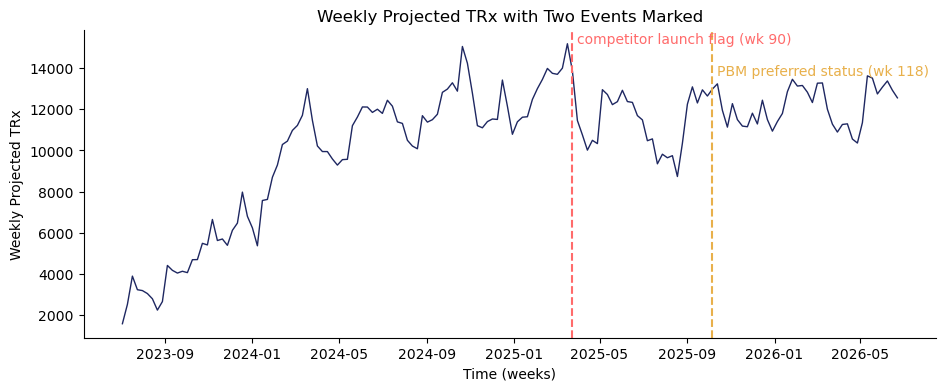

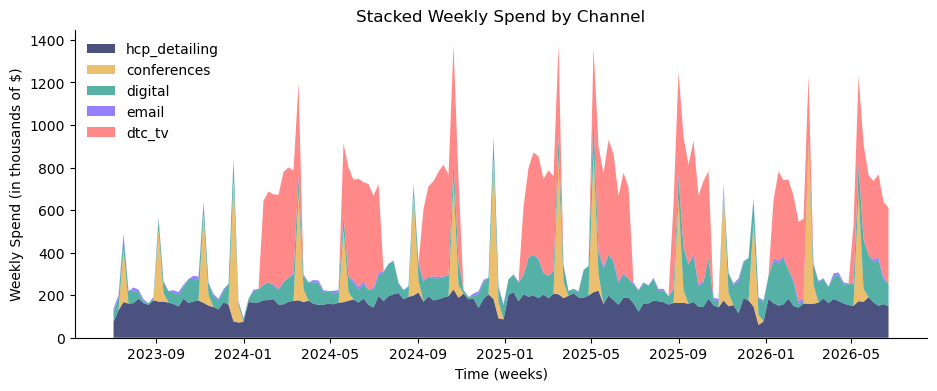

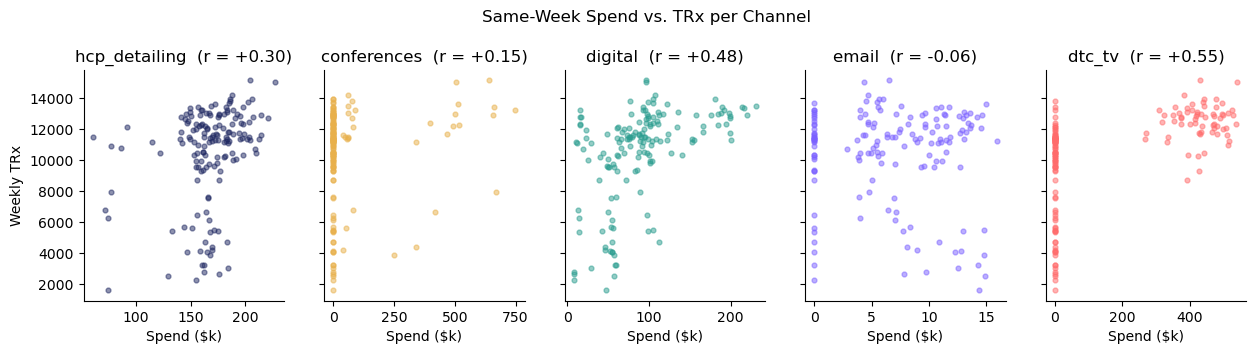

In [4]:
# 1
# weekly TRx with the two events marked (week 90 & 118)
# You have 156 weeks of national data: projected TRx, weekly spend in five channels (HCP detailing, conferences, digital, email, DTC TV), the rep call count, 
# a competitor-launch flag (week 90) and the share of commercial lives with preferred formulary status (which steps up at week 118). 
# You also have the results of a DTC-TV geo holdout run on flight 7. 
fig, ax = plt.subplots()
ax.plot(df.week, df.trx, color=NAVY, lw=1)
ax.axvline(df.week[90], color=CORAL, ls="--")
ax.text(df.week[91], df.trx.max(), "competitor launch flag (wk 90)", color=CORAL)
ax.axvline(df.week[118], color=GOLD, ls="--")
ax.text(df.week[119], df.trx.max() * 0.90, "PBM preferred status (wk 118)", color=GOLD)
ax.set_ylabel("Weekly Projected TRx")
ax.set_xlabel("Time (weeks)")
ax.set_title("Weekly Projected TRx with Two Events Marked")
plt.show()

# stacked weekly spend by channel
fig, ax = plt.subplots()
ax.stackplot(df.week, df[SPEND].T / 1e3, labels=CHANNELS, colors=[PALETTE[c] for c in CHANNELS], alpha=0.8)
ax.set_xlabel("Time (weeks)")
ax.set_ylabel("Weekly Spend (in thousands of $)")
ax.set_title("Stacked Weekly Spend by Channel")
ax.legend(loc="upper left", frameon=False)
plt.show()

# same-week spend vs. TRx per channel with the correlation in the title.
r = df[SPEND].corrwith(df.trx)
fig, axes = plt.subplots(1, 5, figsize=(15, 3), sharey=True)
for ax, c, s in zip(axes, CHANNELS, SPEND):
    ax.scatter(df[s] / 1e3, df.trx, s=12, color=PALETTE[c], alpha=0.5)
    ax.set_title(f"{c}  (r = {r[s]:+.2f})")
    ax.set_xlabel("Spend ($k)")
axes[0].set_ylabel("Weekly TRx")
plt.suptitle("Same-Week Spend vs. TRx per Channel", y=1.08)
plt.show()


* The spends at 0 indicate where marketing is ineffective; must look out for carryover, saturation, and controls

A2. Engineer the controls: a logistic launch ramp (choose midpoint and scale by AIC, not by eye alone), an annual sine/cosine pair, the competitor indicator, and the formulary-access variable. Say in one sentence each why every control is there.

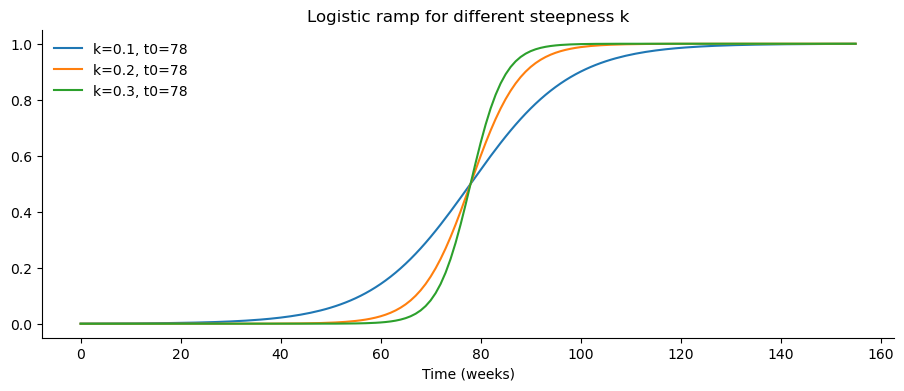

In [5]:
from scipy.optimize import curve_fit
# tt - time (weeks)
# L - height of the climb
# k - steepness of the curve; scale of the growth rate
# t0 - midpoint of the curve
# c - vertical offset
# def logistic(tt, L, k, t0, c):
#     return L / (1 + np.exp(-k * (tt - t0))) + c 
# (L, k, t0, c), _ = curve_fit(logistic, t, df.trx, p0=[df.trx.max(), 0.1, T / 2, df.trx.min()])
def logistic(tt, k, t0):
    return 1 / (1 + np.exp(-k * (tt - t0)))

# demo: how k changes the shape
fig, ax = plt.subplots()
for k in [0.1, 0.2, 0.3]:
    ax.plot(t, logistic(t, k, T / 2), label=f"k={k}, t0={T / 2:.0f}")
ax.legend(frameon=False)
ax.set_xlabel("Time (weeks)")
ax.set_title("Logistic ramp for different steepness k")
plt.show()

    aic  t0    k  dAIC
2635.34  26 0.10  0.00
2635.60  10 0.05  0.26
2636.45  14 0.05  1.10
2639.13  18 0.05  3.79
2639.69  22 0.10  4.35


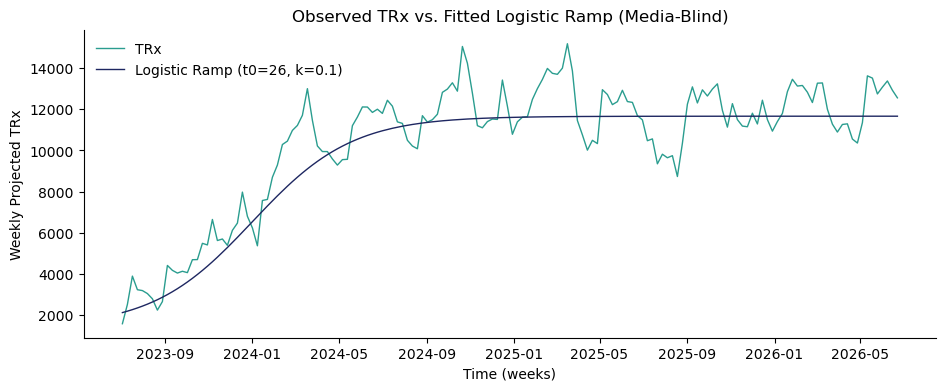

In [6]:
baseline_ctrl = pd.DataFrame({
    "season_sin": np.sin(2 * np.pi * t / 52), "season_cos": np.cos(2 * np.pi * t / 52),
    "competitor_launch": df.competitor_active,
    "pbm_preferred": df.pbm_preferred_share
})

# choose midpoint and steepness by AIC
rows = []
for t0, k in product(range(10, 51, 4), [0.05, 0.1, 0.15, 0.2, 0.3, 0.5]):
    X = sm.add_constant(baseline_ctrl.assign(ramp=logistic(t, k, t0)))
    rows.append((sm.OLS(df.trx, X).fit().aic, t0, k))
ramp_aic = pd.DataFrame(rows, columns=["aic", "t0", "k"]).sort_values("aic")
ramp_aic["dAIC"] = ramp_aic.aic - ramp_aic.aic.min()
print(ramp_aic.head(5).round(2).to_string(index=False))

t0, k = ramp_aic.iloc[0][["t0", "k"]]
baseline_ctrl.insert(0, "ramp", logistic(t, k, t0))
m_ctrl = sm.OLS(df.trx, sm.add_constant(baseline_ctrl)).fit()
ramp_trx = m_ctrl.params["const"] + m_ctrl.params["ramp"] * baseline_ctrl.ramp   # ramp on the TRx scale

fig, ax = plt.subplots()
ax.plot(df.week, df.trx, color=TEAL, lw=1, label="TRx")
ax.plot(df.week, ramp_trx, color=NAVY, lw=1, label=f"Logistic Ramp (t0={t0:.0f}, k={k})")
ax.legend(loc="upper left", frameon=False)
ax.set_ylabel("Weekly Projected TRx")
ax.set_xlabel("Time (weeks)")
ax.set_title("Observed TRx vs. Fitted Logistic Ramp (Media-Blind)")
plt.show()

Why each control is neccesary:
1. The launch ramp is needed to account for how much new brands grow on their own in the way of increased awareness, formulary wins, or refill accumulation
2. Seasonality is needed to measure against deductible resets, refill timing, or the flu season depending on the Rx category
3. Competitor launch is needed to account for share losses that do not correlate with spending
4. Formulary access is needed due to the industry nature since the payer decides whether a script actually gets filled

A3. Show what happens to the channel coefficients when the access control is omitted (refit without it; one small table).

The table needs the channel transforms from Part B and the grid search in task 6, so it is computed right after task 6 (see "A3 table" below).

In [11]:
# A3 table
model, X = fit(best)
m_noacc, _ = fit(best, df, baseline_ctrl.drop(columns="pbm_preferred"))
cols = CHANNELS + ["competitor_launch"]
cmp = pd.DataFrame({"with access": model.params[cols], "without access": m_noacc.params[cols]})
cmp["change_%"] = (cmp["without access"] / cmp["with access"] - 1) * 100
print(cmp.round(1))
print(f"\nAIC with access {model.aic:,.1f} · without {m_noacc.aic:,.1f}")

                   with access  without access  change_%
hcp_detailing           3900.9          2972.6     -23.8
conferences             1084.5          1071.7      -1.2
digital                 2760.7          2913.3       5.5
email                    643.6           679.3       5.5
dtc_tv                  3500.8          3483.7      -0.5
competitor_launch       -843.7          -463.4     -45.1

AIC with access 2,217.5 · without 2,281.0


## Part B — Adstock and saturation (15 pts)

**What excellent looks like:** Correct implementations; clear plots; one-sentence interpretation per parameter; decay ranges justified from channel knowledge.



B4. Implement geometric adstock and Hill saturation as two functions. Plot impulse responses for δ ∈ {0.1, 0.4, 0.7} and Hill curves for three (K, s) pairs; one sentence per parameter.

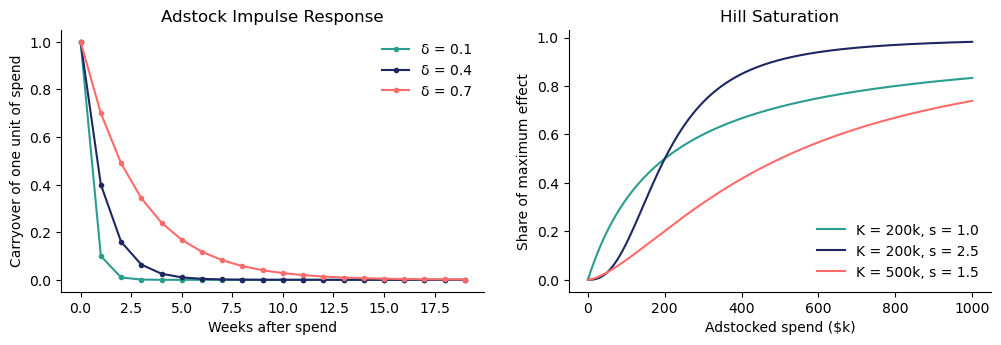

In [7]:
# 4
def geometric_adstock(x, decay):
    a = np.zeros(len(x)); a[0] = x[0]
    for i in range(1, len(x)):
        a[i] = x[i] + decay * a[i - 1]
    return a

def hill(a, K, s):
    a = np.asarray(a, float)
    return a ** s / (a ** s + K ** s + 1e-12)

impulse = np.zeros(20); impulse[0] = 1
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for d, col in zip([0.1, 0.4, 0.7], [TEAL, NAVY, CORAL]):
    axes[0].plot(geometric_adstock(impulse, d), marker="o", ms=3, color=col, label=f"δ = {d}")
axes[0].set_xlabel("Weeks after spend")
axes[0].set_ylabel("Carryover of one unit of spend")
axes[0].set_title("Adstock Impulse Response")
axes[0].legend(frameon=False)

x = np.linspace(0, 1e6, 300)
for (K, s), col in zip([(200e3, 1.0), (200e3, 2.5), (500e3, 1.5)], [TEAL, NAVY, CORAL]):
    axes[1].plot(x / 1e3, hill(x, K, s), color=col, label=f"K = {K / 1e3:.0f}k, s = {s}")
axes[1].set_xlabel("Adstocked spend ($k)")
axes[1].set_ylabel("Share of maximum effect")
axes[1].set_title("Hill Saturation")
axes[1].legend(frameon=False)
plt.show()

Param Interpretation
- Decay δ - how much the previous week's dollar/share impacts the future carryover
- Half-Saturation K - the adstocked spend at which the channel reaches half of its maximum effect
- Shape s (shape) - described the curviness; s = 1 is concave from the start, while s > 1 gives an S-curve with a threshold 

B5. Write down, per channel, the decay range you will allow the search to use and justify each in one line (channel knowledge, not the data). This is your prior.

In [8]:
# 5
DECAY_RANGE = {"hcp_detailing": [0.5, 0.6, 0.7], "conferences": [0.1, 0.25, 0.4], "digital": [0.3, 0.5, 0.7], "email": [0.05, 0.1, 0.25], "dtc_tv": [0.55, 0.7, 0.8]}

Justification of decay (prior ranges for the search)
- HCP detailing (0.5–0.7): large carryover due to long-term relationship building; spending dips over the holidays though
- Conferences (0.1–0.4): a one-off conference creates a sharp spike in attention that fizzles out quickly once stakeholders go back to their normal routines
- Digital (0.3–0.7): impressions and clicks prompt a response within days, so the effect is short-lived; spend grows alongside TV, which is a collinearity risk for the VIF check
- Email (0.05–0.25): a message is opened or ignored within days and has the least carryover of any channel
- TV (0.55–0.8): flights, at-home entertainment, streaming, etc. builds awareness and has the longest carryover

## Part C — OLS MMM and diagnostics (25 pts)

**What excellent looks like:** AIC-selected transforms with runner-up cells; positive media coefficients; VIF discussed; hold-out MAPE reported and honestly interpreted (the formulary step).



C6. Grid-search δ (within your ranges), K (as a multiple of the channel's median adstocked spend) and s per channel by AIC, one channel at a time, at least two sweeps. Report the winning cell and the two runner-up cells per channel with their ΔAIC.

In [9]:
# 6
GRID_KMULT = [0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 4.0, 8.0]   # multiples of the median adstocked spend (weeks > 0)
GRID_SHAPE = [1.0, 1.25, 1.5, 2.0, 2.5]

def transform(spend, p):
    a = geometric_adstock(spend.astype(float), p["decay"])
    K = np.median(a[a > 0]) * p["K_mult"]
    return hill(a, K, p["shape"]), K

def design(params, data=df, controls=baseline_ctrl):
    X = controls.copy()
    for ch, p in params.items():
        X[ch] = transform(data[f"{ch}_spend"].values, p)[0]
    return sm.add_constant(X)

def fit(params, data=df, controls=baseline_ctrl):
    X = design(params, data, controls)
    return sm.OLS(data.trx.values, X).fit(), X

def sweep(best, controls):
    for ch in CHANNELS:
        cands = []
        for d, km, s in product(DECAY_RANGE[ch], GRID_KMULT, GRID_SHAPE):
            trial = {c: dict(best[c]) for c in CHANNELS}; trial[ch] = dict(decay=d, K_mult=km, shape=s)
            cands.append((fit(trial, df, controls)[0].aic, d, km, s))
        aic, d, km, s = min(cands); best[ch] = dict(decay=d, K_mult=km, shape=s)
    return best, aic

best = {ch: dict(decay=0.3, K_mult=1.0, shape=1.0) for ch in CHANNELS}
best, aic = sweep(best, baseline_ctrl); print(f"sweep 1: AIC {aic:,.1f}")

# re-pick the ramp now that the media terms are in the model
rows = []
for t0_, k_ in product(range(10, 51, 4), [0.05, 0.1, 0.15, 0.2, 0.3, 0.5]):
    c_ = baseline_ctrl.copy(); c_["ramp"] = logistic(t, k_, t0_)
    rows.append((fit(best, df, c_)[0].aic, t0_, k_))
aic, t0, k = min(rows); baseline_ctrl["ramp"] = logistic(t, k, t0)
print(f"ramp re-picked: t0={t0}, k={k}, AIC {aic:,.1f}")

best, aic = sweep(best, baseline_ctrl); print(f"sweep 2: AIC {aic:,.1f}")
print(pd.DataFrame(best).T)

sweep 1: AIC 2,241.3
ramp re-picked: t0=26, k=0.1, AIC 2,241.3
sweep 2: AIC 2,217.5
               decay  K_mult  shape
hcp_detailing   0.50    1.50    2.5
conferences     0.40    8.00    2.0
digital         0.30    0.75    1.0
email           0.05    0.50    1.0
dtc_tv          0.70    1.50    2.0


In [10]:
# winning cell and two runner-ups per channel, with the average ROI each implies (used again in task 11)
base_spend = {ch: df[f"{ch}_spend"].values.astype(float) for ch in CHANNELS}
sens = []
for ch in CHANNELS:
    cands = []
    for d, km, s in product(DECAY_RANGE[ch], GRID_KMULT, GRID_SHAPE):
        trial = {c: dict(best[c]) for c in CHANNELS}; trial[ch] = dict(decay=d, K_mult=km, shape=s)
        m, _ = fit(trial); h = transform(base_spend[ch], trial[ch])[0]
        cands.append((m.aic, d, km, s, m.params[ch] * h.sum() * REV_PER_TRX / base_spend[ch].sum()))
    cands.sort()
    for rank, (a, d, km, s, r) in enumerate(cands[:3], 1):
        sens.append(dict(channel=ch, rank=rank, dAIC=a - cands[0][0], decay=d, K_mult=km, shape=s, avg_ROI=r))
sens = pd.DataFrame(sens)
print(sens.round(2).to_string(index=False))

      channel  rank  dAIC  decay  K_mult  shape  avg_ROI
hcp_detailing     1  0.00    0.5    1.50   2.00     1.89
hcp_detailing     2  0.03    0.5    2.00   2.00     1.72
hcp_detailing     3  0.08    0.5    1.50   2.50     1.55
  conferences     1  0.00    0.4    8.00   2.00     1.20
  conferences     2  1.66    0.4    8.00   2.50     1.15
  conferences     3  1.85    0.4    8.00   1.50     1.28
      digital     1  0.00    0.3    1.00   1.00     3.75
      digital     2  0.39    0.3    0.75   1.00     4.15
      digital     3  0.56    0.3    0.75   1.25     3.54
        email     1  0.00    0.1    0.75   1.00    14.75
        email     2  0.08    0.1    0.50   1.00    16.26
        email     3  0.10    0.1    1.00   1.00    13.90
       dtc_tv     1  0.00    0.7    1.50   2.00     1.23
       dtc_tv     2  2.90    0.7    3.00   1.50     1.27
       dtc_tv     3  2.97    0.7    2.00   1.50     1.35


With formulary access in Week 118:
- Competitor coeff decreases by nearly half (844 to 464); heavily mitigates the effect of competition 
- Detailing coeff drops by almost of a quarter (3901 to 2973) despite the bump in TRx

C7. Fit OLS with the chosen transforms and the controls. Report coefficients, R², a residual plot with Durbin–Watson, and VIF for every regressor. Comment on signs and any VIF above 5.

R² = 0.992   adj. R² = 0.991   AIC = 2,217.5   n = 156
                       coef  std_err    p
const             -1123.124  204.909  0.0
ramp               7941.096  117.880  0.0
season_sin         -166.532   34.167  0.0
season_cos         -438.416   36.895  0.0
competitor_launch  -843.745   74.242  0.0
pbm_preferred      3032.327  348.621  0.0
hcp_detailing      3900.877  435.943  0.0
conferences        1084.540   63.422  0.0
digital            2760.651  199.837  0.0
email               643.632   86.193  0.0
dtc_tv             3500.798  108.230  0.0


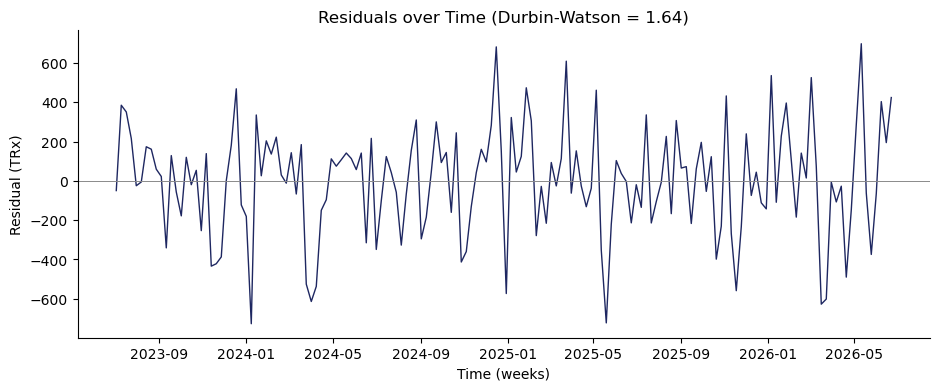


VIF:
ramp                 20.34
season_sin            1.09
season_cos            1.27
competitor_launch     3.63
pbm_preferred        22.75
hcp_detailing        19.00
conferences           1.52
digital              21.86
email                 5.11
dtc_tv                2.72


In [12]:
# 7
print(f"R² = {model.rsquared:.3f}   adj. R² = {model.rsquared_adj:.3f}   AIC = {model.aic:,.1f}   n = {int(model.nobs)}")
print(pd.DataFrame({"coef": model.params, "std_err": model.bse, "p": model.pvalues}).round(3))

resid = model.resid
fig, ax = plt.subplots()
ax.plot(df.week, resid, color=NAVY, lw=1)
ax.axhline(0, color=GREY, lw=0.7)
ax.set_ylabel("Residual (TRx)")
ax.set_xlabel("Time (weeks)")
ax.set_title(f"Residuals over Time (Durbin-Watson = {durbin_watson(resid):.2f})")
plt.show()

Xv = X.drop(columns="const")
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(Xv.shape[1])], index=Xv.columns)
print("\nVIF:"); print(vif.round(2).to_string())

Not separately identified (VIF > 10; potentially shares a time trend):
- ramp 20.3
- pbm_preferred 22.8
- hcp_detailing 19.0
- digital 21.9

Suspicious (VIF 5–10, borderline):
- email 5.1

All five media coefficients are positive; competitor launch is negative while formulary access is positive


C8. Hold-out: refit the coefficients on weeks 1–104 and predict 105–156. Report MAPE overall and split at week 118. State plainly what the model could and could not have forecast, and whether your grid was re-run on the training window.

MAPE overall 4.9% · before formulary step 1.6% · after 6.1%


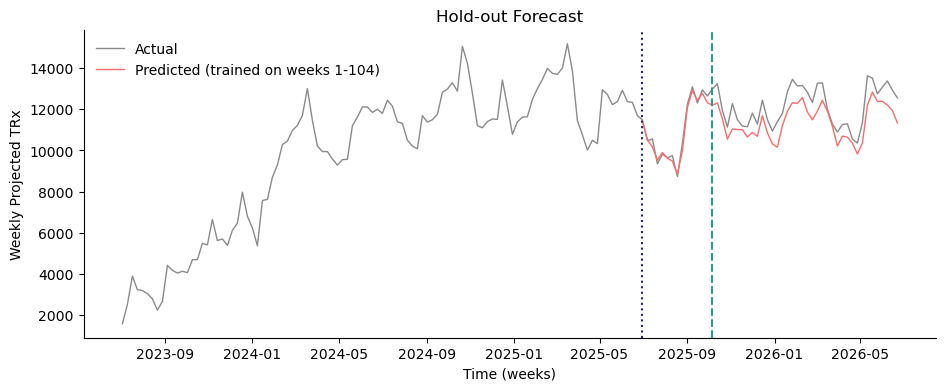

In [13]:
# 8
# access is constant in weeks 1-104, so it is dropped from the training fit
ctrl_tr = baseline_ctrl.drop(columns="pbm_preferred")
X_all = design(best, df, ctrl_tr)          # transforms use the full series so adstock carries across the split
m_tr = sm.OLS(df.trx.values[:104], X_all.iloc[:104]).fit()
pred = m_tr.predict(X_all.iloc[104:]).values
actual = df.trx.values[104:]
ape = np.abs(pred - actual) / actual * 100
step = df.pbm_preferred_share.diff().abs().idxmax() - 104     # position of the formulary step inside the test window
print(f"MAPE overall {ape.mean():.1f}% · before formulary step {ape[:step].mean():.1f}% · after {ape[step:].mean():.1f}%")

fig, ax = plt.subplots()
ax.plot(df.week, df.trx, color=GREY, lw=1, label="Actual")
ax.plot(df.week[104:], pred, color=CORAL, lw=1, label="Predicted (trained on weeks 1-104)")
ax.axvline(df.week[104], color=NAVY, ls=":")
ax.axvline(df.week[118], color=TEAL, ls="--")
ax.legend(loc="upper left", frameon=False)
ax.set_ylabel("Weekly Projected TRx")
ax.set_xlabel("Time (weeks)")
ax.set_title("Hold-out Forecast")
plt.show()

Model Limitations
- Grid was not rerun on the training window; this hold-out evaluates coeffs estimated on weeks 1–104, but it is not a fully out-of-sample test because the hyperparameters were selected using all 156 weeks
- The formulary change occurs at week 118, after the training period. Forecast errors are low before the change (so the model could forecast baseline trend, seasonality, competitor effect, & media response) but then increases afterward (so the modle couldn't forecast the formulary step), suggesting the model does not accurately capture teh shift in demand and is biased after week 118

## Part D — Decomposition and ROI with ranges (15 pts)

**What excellent looks like:** Clean, labeled decomposition; average and marginal tables agree with the model; bootstrap and grid-sensitivity ranges on one chart; geo-holdout comparison done.


D9. Stacked-area decomposition of base + per-channel contributions over all 156 weeks with actual TRx overlaid; base and incremental shares in the caption.

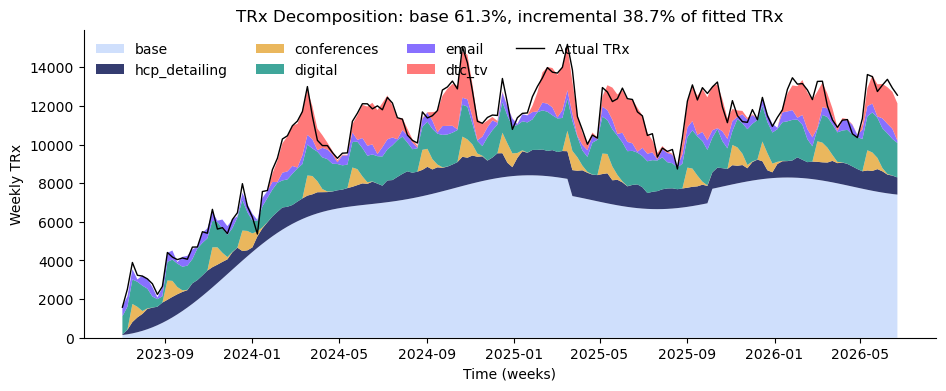

Share of fitted TRx (%):
base             61.3
hcp_detailing     9.9
conferences       2.7
digital          14.3
email             3.4
dtc_tv            8.3

Incremental (all channels): 38.7% of TRx  ·  Unexplained: -0 TRx (-0.00%)


In [23]:
# 9
contrib = pd.DataFrame(index=df.index)
for ch in CHANNELS:
    contrib[ch] = model.params[ch] * transform(base_spend[ch], best[ch])[0]
base = model.params["const"] + (X[baseline_ctrl.columns] * model.params[baseline_ctrl.columns]).sum(axis=1)
contrib.insert(0, "base", base.values)
share = contrib.sum() / contrib.sum().sum() * 100

fig, ax = plt.subplots()
ax.stackplot(df.week, contrib.T.values, labels=contrib.columns, colors=[PALETTE[c] for c in contrib.columns], alpha=0.9)
ax.plot(df.week, df.trx, color="black", lw=1, label="Actual TRx")
ax.legend(loc="upper left", ncol=4, frameon=False)
ax.set_ylabel("Weekly TRx")
ax.set_xlabel("Time (weeks)")
ax.set_title(f"TRx Decomposition: base {share['base']:.1f}%, incremental {100 - share['base']:.1f}% of fitted TRx")
plt.show()

# incremental shares
inc = contrib.drop(columns="base").sum()
inc_share = inc / inc.sum() * 100

summary = pd.DataFrame({
    "pct_of_total": share,
    "pct_of_incremental": inc_share,
}).round(1)
share = (contrib.sum() / contrib.sum().sum() * 100).round(1)
print("Share of fitted TRx (%):"); print(share.to_string())
unexpl = df.trx.sum() - contrib.sum().sum()
print(f"\nIncremental (all channels): {100-share['base']:.1f}% of TRx  ·  Unexplained: {unexpl:,.0f} TRx ({unexpl/df.trx.sum()*100:.2f}%)")


D10. Table of spend, incremental TRx, average ROI and marginal ROI (+5% in every week) per channel, ranked both ways.


In [15]:
# 10
def predict_total(spend):
    total = base.values.copy()
    for ch in CHANNELS:
        a = geometric_adstock(spend[ch], best[ch]["decay"])
        K = transform(base_spend[ch], best[ch])[1]       # K stays at its fitted value in any scenario
        total = total + model.params[ch] * hill(a, K, best[ch]["shape"])
    return total.sum()

base_total = predict_total(base_spend)
rows = []
for ch in CHANNELS:
    sp = base_spend[ch].sum(); tr = contrib[ch].sum()
    bumped = {c: v.copy() for c, v in base_spend.items()}; bumped[ch] = bumped[ch] * 1.05
    d_trx = predict_total(bumped) - base_total
    rows.append(dict(channel=ch, spend_M=sp / 1e6, incremental_trx=tr, avg_ROI=tr * REV_PER_TRX / sp, marginal_ROI=d_trx * REV_PER_TRX / (sp * 0.05)))
roi = pd.DataFrame(rows).set_index("channel")
roi["rank_avg"] = roi.avg_ROI.rank(ascending=False).astype(int)
roi["rank_marginal"] = roi.marginal_ROI.rank(ascending=False).astype(int)
print(roi.round(2))

               spend_M  incremental_trx  avg_ROI  marginal_ROI  rank_avg  rank_marginal
channel                                                                                
hcp_detailing    26.10        161853.05     1.55          2.79         3              2
conferences       9.07         43410.59     1.20          0.52         5              5
digital          14.08        233496.36     4.15          1.71         2              3
email             1.04         55965.83    13.41          4.04         1              1
dtc_tv           27.56        135712.88     1.23          1.20         4              4


D11. Ranges: a moving-block bootstrap of the residuals (≥ 200 refits, blocks of 8–13 weeks) for 80% intervals on average ROI, plus the ROI implied by each channel's runner-up grid cells. One chart with both.


                 p10    p50    p90  point
hcp_detailing   1.32   1.53   1.78   1.55
conferences     1.08   1.20   1.29   1.20
digital         3.82   4.15   4.51   4.15
email          11.05  13.37  15.52  13.41
dtc_tv          1.18   1.23   1.28   1.23


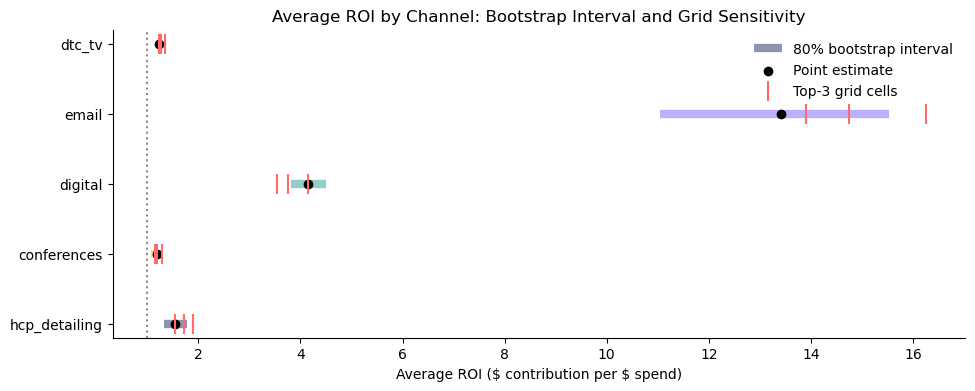

In [28]:
# 11
B, BLOCK = 300, 10
fitted = model.fittedvalues.values; res = model.resid.values
h = {ch: transform(base_spend[ch], best[ch])[0] for ch in CHANNELS}
boot = {ch: [] for ch in CHANNELS}
for b in range(B):
    starts = rng.integers(0, T - BLOCK, size=T // BLOCK + 1)
    e = np.concatenate([res[s:s + BLOCK] for s in starts])[:T]
    m_b = sm.OLS(fitted + e, X).fit()
    for ch in CHANNELS:
        boot[ch].append(m_b.params[ch] * h[ch].sum() * REV_PER_TRX / base_spend[ch].sum())
ci = pd.DataFrame({ch: np.percentile(boot[ch], [10, 50, 90]) for ch in CHANNELS}, index=["p10", "p50", "p90"]).T
ci["point"] = roi.avg_ROI
print(ci.round(2))

fig, ax = plt.subplots()
y = np.arange(len(CHANNELS))
ax.hlines(y, ci.p10, ci.p90, color=[PALETTE[c] for c in CHANNELS], lw=6, alpha=0.5, label="80% bootstrap interval")
ax.scatter(ci.point, y, color="black", zorder=3, label="Point estimate")
for i, ch in enumerate(CHANNELS):
    rr = sens[sens.channel == ch].avg_ROI
    ax.scatter(rr, [i] * len(rr), marker="|", s=200, color=CORAL, zorder=4, label="Top-3 grid cells" if i == 0 else None)
ax.set_yticks(y); ax.set_yticklabels(CHANNELS)
ax.axvline(1, color=GREY, ls=":")
ax.legend(frameon=False)
ax.set_xlabel("Average ROI (\$ contribution per \$ spend)")
ax.set_title("Average ROI by Channel: Bootstrap Interval and Grid Sensitivity")
plt.show()

D12. Calibration: compute the difference-in-differences lift and implied ROI from the geo holdout, and compare it with the MMM's view of the same flight. Two sentences on whether they agree and what you would do if they did not.

period     pre   test  dmas
group                      
exposed  74139  82959    30
holdout  17719  17453    10

exposed growth 1.119 · holdout growth 0.985 → incremental TRx 9,933 (13.6% lift)
TV spend in exposed DMAs during test: $2.36M → geo ROI 1.05
MMM-implied ROI for the same flight: 0.99 (all-period MMM average ROI for TV: 1.23)


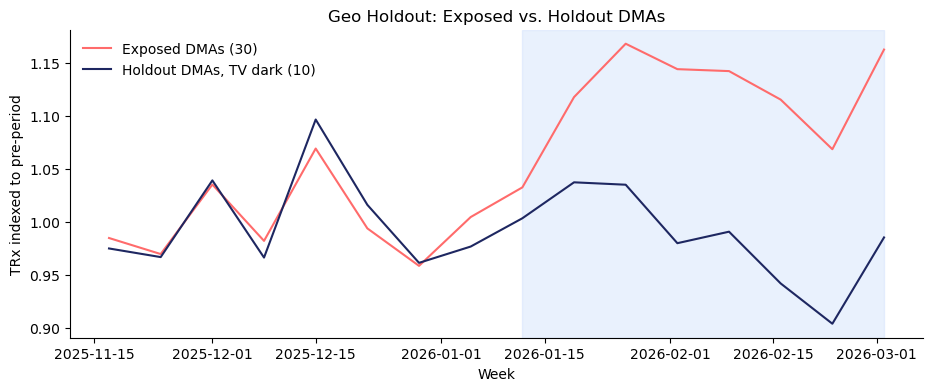

In [27]:
# 12
geo = pd.read_csv(DATA / "glucoren_geo_lift_dtc_tv.csv", parse_dates=["week"])
cell = geo.groupby(["group", "period"]).trx.sum().unstack("period")
n_dma = geo.groupby("group").dma.nunique()
print(cell.assign(dmas=n_dma))


# difference-in-differences: holdout growth applied to the exposed pre-period level gives the counterfactual
g_hold = cell.loc["holdout", "test"] / cell.loc["holdout", "pre"]
g_exp = cell.loc["exposed", "test"] / cell.loc["exposed", "pre"]
counterfactual = cell.loc["exposed", "pre"] * g_hold
lift_trx = cell.loc["exposed", "test"] - counterfactual
lift_pct = lift_trx / counterfactual * 100
tv_spend = geo[(geo.period == "test") & (geo.group == "exposed")].dtc_tv_spend_alloc.sum()
geo_roi = lift_trx * REV_PER_TRX / tv_spend
print(f"\nexposed growth {g_exp:.3f} · holdout growth {g_hold:.3f} → incremental TRx {lift_trx:,.0f} ({lift_pct:.1f}% lift)")
print(f"TV spend in exposed DMAs during test: ${tv_spend / 1e6:.2f}M → geo ROI {geo_roi:.2f}")

# the MMM's view of the same flight: fitted TV contribution in the test weeks, scaled to the exposed DMAs' share of TRx
test_idx = df.index[df.week.isin(geo[geo.period == "test"].week.unique())]
exposed_share = geo[(geo.period == "pre") & (geo.group == "exposed")].trx.sum() / geo[geo.period == "pre"].trx.sum()
mmm_roi = contrib.loc[test_idx, "dtc_tv"].sum() * exposed_share * REV_PER_TRX / tv_spend
print(f"MMM-implied ROI for the same flight: {mmm_roi:.2f} (all-period MMM average ROI for TV: {roi.loc['dtc_tv', 'avg_ROI']:.2f})")

piv = geo.groupby(["group", "week"]).trx.sum().unstack("group")
piv = piv / piv.iloc[:8].mean()
fig, ax = plt.subplots()
ax.plot(piv.index, piv.exposed, color=CORAL, lw=1.5, label=f"Exposed DMAs ({n_dma['exposed']})")
ax.plot(piv.index, piv.holdout, color=NAVY, lw=1.5, label=f"Holdout DMAs, TV dark ({n_dma['holdout']})")
ax.axvspan(geo[geo.period == "test"].week.min(), geo.week.max(), color=ICE, alpha=0.4)
ax.legend(frameon=False)
ax.set_ylabel("TRx indexed to pre-period")
ax.set_xlabel("Week")
ax.set_title("Geo Holdout: Exposed vs. Holdout DMAs")
plt.show()

Interpretation:
- The geo holdout shows a 13.6% lift and an ROI of 1.05. The MMM implies 0.99 for the same flight and DMAs, so the two agree within ~6% and the model's TV estimate holds up.
- The all-period MMM average for TV (1.23) is higher than both because the experiment measures *this* flight, in *these* DMAs, at *this* point in the launch, while the MMM averages over three years of flights.
- If they disagreed, I would trust the experiment (cleaner identification), and use it to calibrate the TV coefficient ($\beta_{TV}$), and run a second flight to see whether the gap was specific to flight 7.


In [31]:
# 13 (class Section 11, with one change: also return the proposed spend `cur`)
def scenario(max_move_M, step_M=0.25, floors=None, caps=None):
    floors = floors or {"hcp_detailing": 0.85, "conferences": 0.60, "digital": 0.5, "email": 0.5, "dtc_tv": 0.5}
    caps = caps or {"hcp_detailing": 1.3, "conferences": 1.3, "digital": 1.8, "email": 2.5, "dtc_tv": 1.3} # flagged cap
    cur = {c: v.copy() for c, v in base_spend.items()}; moved = 0.0
    def marg(sp, ch, sign):
        s = {c: v.copy() for c, v in sp.items()}; s[ch] = s[ch] * (1 + sign * step_M * 1e6 / s[ch].sum())
        return (predict_total(s) - predict_total(sp)) * REV_PER_TRX / (step_M * 1e6) * sign
    while moved < max_move_M:
        m_up = {c: marg(cur, c, +1) for c in CHANNELS if cur[c].sum() + step_M * 1e6 <= caps[c] * base_spend[c].sum()}
        m_dn = {c: marg(cur, c, -1) for c in CHANNELS if cur[c].sum() - step_M * 1e6 >= floors[c] * base_spend[c].sum()}
        if not m_up or not m_dn: break
        to, frm = max(m_up, key=m_up.get), min(m_dn, key=m_dn.get)
        if to == frm or m_up[to] - m_dn[frm] < 0.15: break
        cur[to] = cur[to] * (1 + step_M * 1e6 / cur[to].sum()); cur[frm] = cur[frm] * (1 - step_M * 1e6 / cur[frm].sum()); moved += step_M
    out = pd.DataFrame({"current_$M": {c: base_spend[c].sum() / 1e6 for c in CHANNELS},
                        "proposed_$M": {c: cur[c].sum() / 1e6 for c in CHANNELS}})
    out["change_$M"] = out["proposed_$M"] - out["current_$M"]
    out["vs_cap_or_floor"] = [("at cap" if cur[c].sum() >= 0.98 * caps[c] * base_spend[c].sum()
                               else "at floor" if cur[c].sum() <= 1.02 * floors[c] * base_spend[c].sum() else "")
                              for c in CHANNELS]
    return out.round(2), predict_total(cur) - base_total, moved, cur

# TRx effect of each posture, point estimate + 80% bootstrap range
def hill_sum(spend, ch):
    a = geometric_adstock(spend, best[ch]["decay"]); K = transform(base_spend[ch], best[ch])[1]
    return hill(a, K, best[ch]["shape"]).sum()

rng2 = np.random.default_rng(7)
betas = []                                   # one row of media coefficients per refit
for b in range(B):
    starts = rng2.integers(0, T - BLOCK, size=T // BLOCK + 1)
    e = np.concatenate([res[s:s + BLOCK] for s in starts])[:T]
    betas.append(sm.OLS(fitted + e, X).fit().params[CHANNELS])
betas = pd.DataFrame(betas)

for name, mm in [("Conservative (<= $5M moved)", 5), ("Aggressive (<= $15M moved)", 15)]:
    tbl, gain, moved, cur = scenario(mm)
    dh = pd.Series({ch: hill_sum(cur[ch], ch) - hill_sum(base_spend[ch], ch) for ch in CHANNELS})
    g = betas @ dh                            # TRx gain under each refit
    lo, hi = np.percentile(g, [10, 90])
    print(f"\n{name}: moved ${moved:.2f}M over 3 yrs (~${moved/3:.2f}M/yr)")
    print(f"  TRx gain {gain:,.0f} (80% range {lo:,.0f} to {hi:,.0f}) = {gain/df.trx.sum()*100:.1f}% of TRx")
    print(tbl)


Conservative (<= $5M moved): moved $5.00M over 3 yrs (~$1.67M/yr)
  TRx gain 39,544 (80% range 32,325 to 46,018) = 2.4% of TRx
               current_$M  proposed_$M  change_$M vs_cap_or_floor
hcp_detailing       26.10        30.60        4.5                
conferences          9.07         5.57       -3.5                
digital             14.08        14.08        0.0                
email                1.04         1.54        0.5                
dtc_tv              27.56        26.06       -1.5                

Aggressive (<= $15M moved): moved $10.25M over 3 yrs (~$3.42M/yr)
  TRx gain 59,923 (80% range 47,304 to 71,228) = 3.7% of TRx
               current_$M  proposed_$M  change_$M vs_cap_or_floor
hcp_detailing       26.10        33.85       7.75          at cap
conferences          9.07         5.57      -3.50                
digital             14.08        15.33       1.25                
email                1.04         2.29       1.25                
dtc_tv            


## Part E — The reallocation memo (35 pts)

Write a two-page memo to the GLUCOREN Brand Lead. Readable by a non-technical executive; defensible to a quantitative reviewer

**What excellent looks like:** Clear TL;DR; reallocation specific, feasible and on a fixed total in two postures; acknowledges what the model misses; ends with a costed experiment.

# TLDR:
A one-paragraph TL;DR at the top: what to cut, what to grow, the expected TRx effect with a range, and the one number you are least sure of.
- What to cut: conferences. It ranks last of all our channels spend with a marginal ROI of 0.52, meaning that each dollar spend returns 52 cents. Then after that, cutting off TV spending is second best with a marginal ROI of 1.20 (See Section D10).
- What to grow: email has the highest marginal ROI at 4.04, followed by detailing at 2.79 (See Section D10). 
- What the expected TRx effect with a range is (See last code block): Moving $5M (conservative) or $10.3M (aggressive) on a fixed total budget is expected to bring about 39.5k TRx (80% range 32,300 - 46,000, +2.4%) or 59.9k TRx (47,300 - 71,200, +3.7%) over the 3 year period. See code above, which provides a reallocation with specific channels and dollar moves on a fixed total, in two risk postures 
    - The constraint that binds first: For the conservative, there is a floor that is being held on conferences ($5.57M); cap is just the $5M budget amount. For the aggresive, there is similarly a floor that is being held on conferences; detailing hits a 1.3x cap, which is flagged in the final section of the code. 
    - Note on feasibility: Medical-legal-regulatory review is required for the release of new content in digital/email channels so the timing may limit the rate of spending. Contracts in regards to things like conferences or TV committments may slow us down from acting on our reccomendations. Hiring reps will also take time to train, so budget increases to detailing won't see an immediate effect. 
- One number we are least sure of: The detailing ROI. With a high VIF of 19, it is cofounded with ramp (20.3), pbm_preferred (22.8), and digital (21.9). In other words, they share a common time trend where our model can't cleanly separate out the effects of each individual factor. 


# The Decomposition Chart

![TRx decomposition](output.png)

Summary: Our base is 61.3% of TRx while media accounts for the rest of the 38.7%; from all media channels, digital (14.3%) and detailing (9.9%) are the largest contributors

# What the Model Doesn't Capture 
- Some factors aren't being actively captured (i.e. copay programs, samples, prices), so its effects may be seen in the base, ramp, and/or channel coeffs. Panel restatements require that past TRx numbers get revised, so model misalignment may occur and must be carefully disambiguated. MLR cycles, as mentioned previously, limits how rapidly spending can grow/vary. Anything with no variation in the data such as formulary access and detailing spend, by their nature, can't be measured if they never change. Another design thig we referenced earlier in the notebook that isn't captures was hold-out limits (See Section C8).



# One Concrete Experiment 
- A test which would tighten our least certain estimate, being detailing, would start off by randomly selecting, say 30% of territories, that are matched on baseline prescriptions. 
    - Then, we stop detailing for about 14 weeks. 
    - The cost would come out to $157.5K per week × 30% × 14 weeks => $0.66M and the lost contribution would be $661,500 × 1.55 ≈ $1.03M, or about 4,100 TRx at $250. Thus, this leaves us with a net cost of $1.03M - $0.66M = $0.36M. 
    - If the measured detailing ROI is close to 1.55 or higher, I would keep the planned increase in detailing as our decision rule. But if the ROI is much lower (like below 1.1; similar to TV and conferences), I would shift that increase into email and digital insted.

## AI Usage Disclosure

I used Claude (Anthropic's Claude Code, in VS Code) as a debugging and explanation aid while working in this notebook. I asked it to review the assignment PDF and the Week 3 class notebook and tell me which tasks were required versus optional. It suggested code for the incremental-share calculation in task 9, a marginal-ROI panel for task 11, and a small change to the geo-holdout table in task 12. I adapted these to my own variable names. The reallocation memo is my own writing and reasoning.
